# 08 · How much accuracy do the GLMs give up? LightGBM benchmark with SHAP

The earlier notebooks favoured interpretable GLMs. This notebook checks the cost of that choice by fitting
gradient-boosted trees to the same targets, with the same features and the same temporal split
(train FY2013-2021, test FY2022-23):

1. **Modification counts:** NB GLM vs LightGBM with a Poisson objective and the same exposure offset. Metric:
   mean Poisson deviance on the test cohort.
2. **Does the ceiling grow?** Logistic regression vs LightGBM classifier. Metrics: ROC AUC and log loss.

SHAP values then show what the trees learned that the GLM's linear-in-log terms could not.

In [1]:
import sys; sys.path.append("..")
import warnings
import lightgbm as lgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import log_loss, mean_poisson_deviance, roc_auc_score
from src.features import RHS, load_awards, model_frame

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
df = model_frame(load_awards())
train = df[df["base_fiscal_year"] <= 2021].copy()
test = df[df["base_fiscal_year"] > 2021].copy()

# Both model families get the fiscal year as a linear trend so the unseen cohorts can be scored.
rhs = RHS.replace("C(base_fiscal_year)", "base_fiscal_year")
NUM = ["log_ceiling", "log_planned_years", "log_offers", "offers_missing", "single_offer", "small_business",
       "commercial_item", "performance_based", "log_solicitation_days", "solicitation_missing", "september",
       "final_two_weeks", "base_fiscal_year"]
CAT = ["pricing", "competition", "award_kind", "psc_group", "sub_agency"]

def lgb_frame(d):
    out = d[NUM + CAT].copy()
    for c in CAT:
        out[c] = pd.Categorical(out[c], categories=sorted(df[c].unique()))
    return out

Xtr, Xte = lgb_frame(train), lgb_frame(test)

## 1. Modification counts: NB GLM vs LightGBM (Poisson)

Both models predict the expected number of modifications. The GLM uses the planned length as an offset and also
as a covariate, so its exposure elasticity is estimated (1 + β), not fixed at 1. LightGBM gets the planned length
as an ordinary feature. A first version passed it as a fixed offset (`init_score`) instead: for contracts planned
to last only days, that implies huge per-year rates, and the trees produced predictions in the thousands.
Learning the exposure relationship is the fairer comparison. The NB model is fitted by maximum likelihood as in notebook 02.

In [2]:
nb_mle = smf.negativebinomial("n_mods ~ " + rhs, train, offset=train["log_planned_years"]).fit(
    method="bfgs", maxiter=2000, disp=0)
glm_pred = nb_mle.predict(test, offset=test["log_planned_years"])

params = dict(objective="poisson", learning_rate=0.03, num_leaves=31, min_child_samples=100,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)
dtrain = lgb.Dataset(Xtr, train["n_mods"])
# Early stopping on the last training cohort (FY2021) keeps the test cohort untouched.
val_mask = train["base_fiscal_year"] == 2021
dfit = lgb.Dataset(Xtr[~val_mask], train.loc[~val_mask, "n_mods"])
dval = lgb.Dataset(Xtr[val_mask], train.loc[val_mask, "n_mods"])
probe = lgb.train(params, dfit, 3000, valid_sets=[dval], callbacks=[lgb.early_stopping(100, verbose=False)])
gbm_counts = lgb.train(params, dtrain, probe.best_iteration)
gbm_pred = gbm_counts.predict(Xte)

null_pred = np.full(len(test), train["n_mods"].mean())
res_counts = pd.DataFrame({
    "mean Poisson deviance": [mean_poisson_deviance(test["n_mods"], p) for p in [null_pred, glm_pred, gbm_pred]],
}, index=["constant mean", "NB GLM", "LightGBM"])
res_counts["deviance explained vs constant"] = 1 - res_counts.iloc[:, 0] / res_counts.iloc[0, 0]
print(f"LightGBM trees: {probe.best_iteration}")
res_counts.round(4)

LightGBM trees: 579


,mean Poisson deviance,deviance explained vs constant
constant mean,5.6643,0.0000
NB GLM,2.7573,0.5132
LightGBM,2.3949,0.5772


## 2. Does the ceiling grow? Logistic vs LightGBM

In [3]:
logit = smf.logit("any_growth ~ " + rhs, train).fit(disp=0)
p_logit = logit.predict(test)

cparams = dict(objective="binary", learning_rate=0.03, num_leaves=31, min_child_samples=100, subsample=0.8,
               subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)
probe_c = lgb.train(cparams, lgb.Dataset(Xtr[~val_mask], train.loc[~val_mask, "any_growth"]), 3000,
                    valid_sets=[lgb.Dataset(Xtr[val_mask], train.loc[val_mask, "any_growth"])],
                    callbacks=[lgb.early_stopping(100, verbose=False)])
gbm_cls = lgb.train(cparams, lgb.Dataset(Xtr, train["any_growth"]), probe_c.best_iteration)
p_gbm = gbm_cls.predict(Xte)

pd.DataFrame({
    "ROC AUC": [roc_auc_score(test["any_growth"], p) for p in [p_logit, p_gbm]],
    "log loss": [log_loss(test["any_growth"], p) for p in [p_logit, p_gbm]],
}, index=["logistic GLM", "LightGBM"]).round(4)

,ROC AUC,log loss
logistic GLM,0.7358,0.5162
LightGBM,0.7706,0.4878


## 3. What do the trees see that the GLM misses?

SHAP values split each prediction (on the log-rate scale for the count model) into per-feature contributions.
The summary plot ranks features by overall importance. The dependence plots compare the trees' learned shape for
the two continuous size variables with the GLM's straight line.

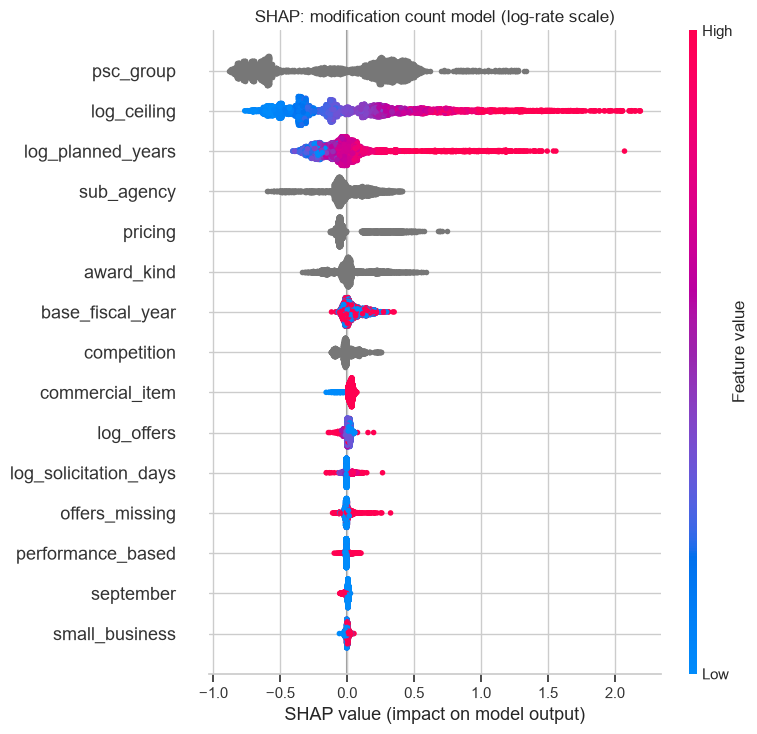

In [4]:
sample = Xte.sample(5000, random_state=0)
explainer = shap.TreeExplainer(gbm_counts)
sv = explainer.shap_values(sample)
shap.summary_plot(sv, sample, show=False, max_display=15)
plt.title("SHAP: modification count model (log-rate scale)")
plt.tight_layout(); plt.savefig(FIG + "08_shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()

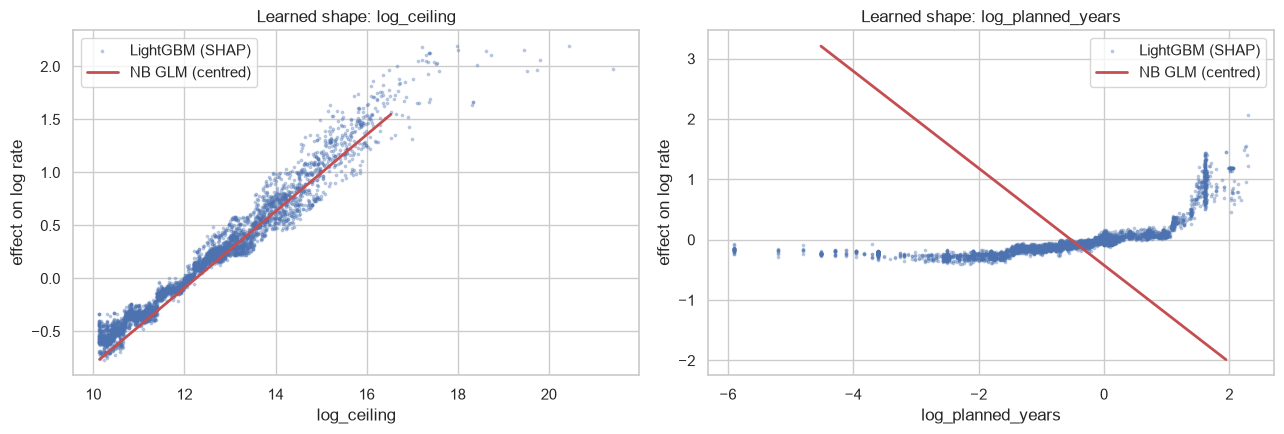

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, feat in zip(ax, ["log_ceiling", "log_planned_years"]):
    j = list(sample.columns).index(feat)
    a.scatter(sample[feat], sv[:, j], s=3, alpha=0.3, label="LightGBM (SHAP)")
    xs = np.linspace(sample[feat].quantile(0.01), sample[feat].quantile(0.99), 50)
    a.plot(xs, nb_mle.params[feat] * (xs - sample[feat].mean()), "r", lw=2, label="NB GLM (centred)")
    a.set(xlabel=feat, ylabel="effect on log rate", title=f"Learned shape: {feat}"); a.legend()
plt.tight_layout(); plt.savefig(FIG + "08_shap_vs_glm.png", dpi=120); plt.show()

The GLM forces both effects to be straight lines on the log scale. Where the SHAP cloud bends away from the red
line, the trees have found curvature that the GLM misses: for example, modifications that level off for very
long contracts instead of growing in proportion to planned length.

## Findings

- **LightGBM wins, but not by much.** On the held-out FY2022-23 cohort it explains 58% of the Poisson deviance in
  modification counts against 51% for the NB GLM, and reaches AUC 0.771 vs 0.736 for the logistic GLM on growth.
- **Most of that gap closes with better features rather than a different model.** The lasso-logistic model in
  notebook 05, given detailed product codes, industries, offices and vendors, reaches AUC 0.766 while staying
  linear and interpretable.
- **SHAP agrees with the GLMs on the main drivers:** size, planned length, products vs services and pricing type
  lead both. Where the trees differ is curvature. Their effects for size and length bend where the GLM is forced
  to be a straight line on the log scale. Splines on those two terms are the natural next step for the GLM.
- **Takeaway for model choice:** for explaining *why* contracts change, the GLMs give up ~5 points of AUC or ~7 points
  of deviance explained in exchange for coefficients that can be tested and defended. For pure risk scoring, the
  boosted model is the better tool.